In [1]:
import os
import cv2
import yaml
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ultralytics import YOLO

In [2]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.5.1
CUDA Available: True
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [3]:
with open("data/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print(data)

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 7, 'names': ['Enemy_Champ', 'Enemy_Minion', 'Enemy_Turret', 'Friend_Champ', 'Friend_Minion', 'Friend_Turret', 'Player_Champ'], 'roboflow': {'workspace': 'lolbotdetection', 'project': 'leaguebotdetection', 'version': 7, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/lolbotdetection/leaguebotdetection/dataset/7'}}


In [4]:
train_images = list(Path("data/train/images").glob("*"))
valid_images = list(Path("data/valid/images").glob("*"))
test_images = list(Path("data/test/images").glob("*"))

print("Train:", len(train_images))
print("Valid:", len(valid_images))
print("Test :", len(test_images))

Train: 1746
Valid: 187
Test : 128


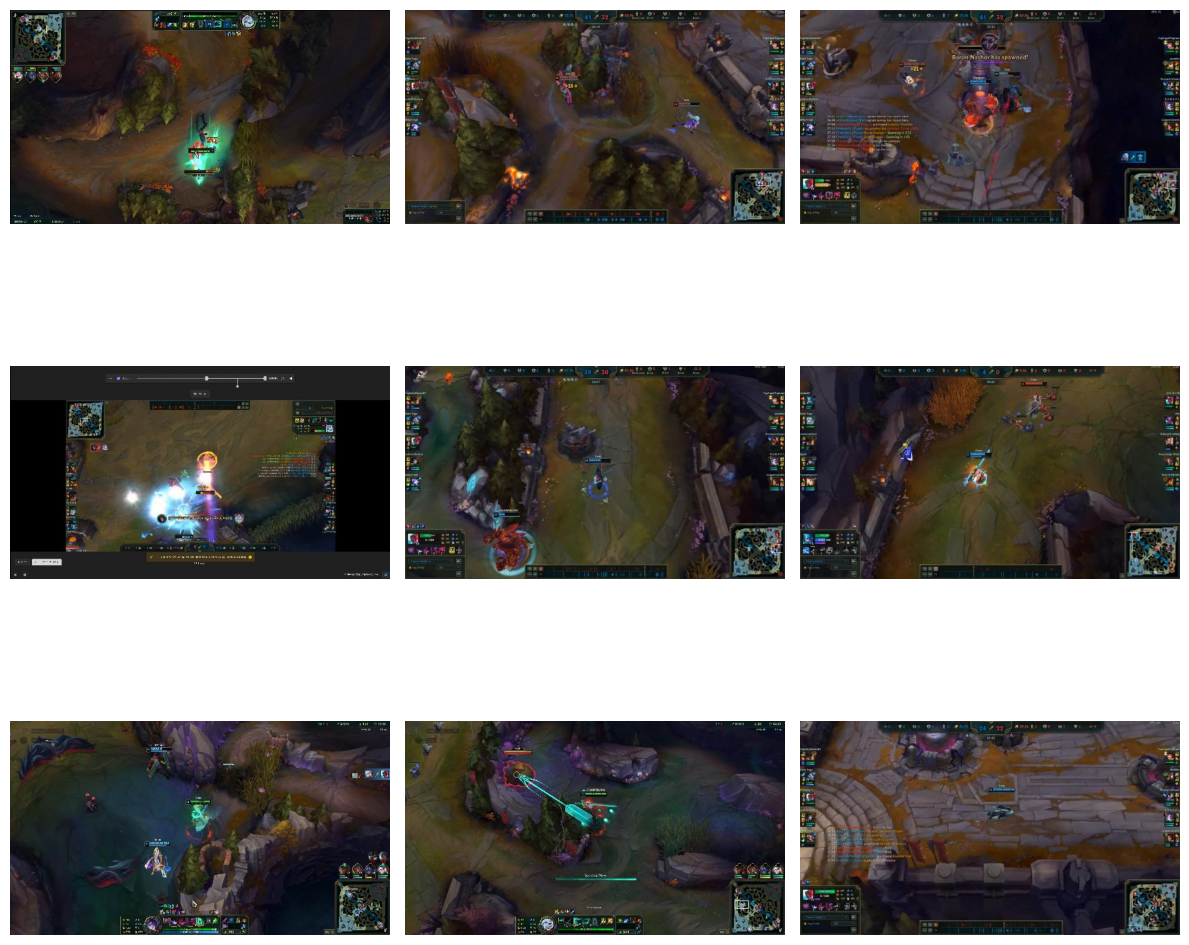

In [5]:
sample_images = random.sample(train_images, 9)

plt.figure(figsize=(12,12))

for i, img_path in enumerate(sample_images):

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

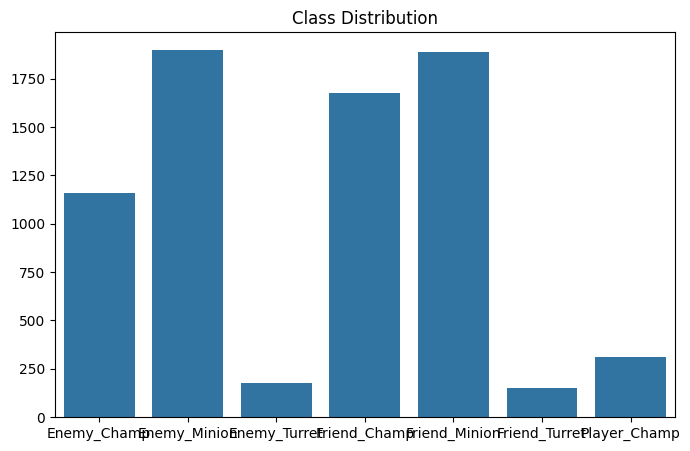

{0: 1161, 1: 1896, 2: 174, 3: 1675, 4: 1886, 5: 149, 6: 309}


In [6]:
class_counts = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0}

label_files = list(Path("data/train/labels").glob("*.txt"))

for label_file in label_files:

    with open(label_file,"r") as f:

        lines = f.readlines()

        for line in lines:

            cls = int(line.split()[0])
            class_counts[cls] += 1

names = data["names"]   # pulls directly from your loaded data.yaml — no hardcoding needed

counts = [class_counts[i] for i in range(len(names))]

plt.figure(figsize=(8,5))
sns.barplot(x=names, y=counts)
plt.title("Class Distribution")
plt.show()

print(class_counts)

In [7]:
model = YOLO("yolov8m (1).pt")

In [9]:
from ultralytics.data.utils import check_det_dataset

check_det_dataset("data/data.yaml")

{'train': 'C:\\Users\\ybarg\\OneDrive\\Bureau\\last version\\data\\train\\images',
 'val': 'C:\\Users\\ybarg\\OneDrive\\Bureau\\last version\\data\\valid\\images',
 'test': 'C:\\Users\\ybarg\\OneDrive\\Bureau\\last version\\data\\test\\images',
 'nc': 7,
 'names': {0: 'Enemy_Champ',
  1: 'Enemy_Minion',
  2: 'Enemy_Turret',
  3: 'Friend_Champ',
  4: 'Friend_Minion',
  5: 'Friend_Turret',
  6: 'Player_Champ'},
 'roboflow': {'workspace': 'lolbotdetection',
  'project': 'leaguebotdetection',
  'version': 7,
  'license': 'CC BY 4.0',
  'url': 'https://universe.roboflow.com/lolbotdetection/leaguebotdetection/dataset/7'},
 'yaml_file': 'data\\data.yaml',
 'channels': 3,
 'path': WindowsPath('data')}

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

results = model.train(
    data="/kaggle/input/datasets/youssefbarghouthe/leaguebotdetection-v7i-yolov8/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    optimizer="AdamW",
    amp=True,
    # FIX 1: Turned caching off to prevent the long, silent data-loading delay
    cache=False, 
    # FIX 2: Set workers to 0 to prevent silent multi-processing hangs (common on Windows)
    workers=0,   
    cos_lr=True,
    patience=20,
    close_mosaic=10,
    project="EsportsAnalyzer",
    name="YOLOv8m",
    # FIX 3: Explicitly force YOLO to print its training progress
    verbose=True 
)

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/input/datasets/youssefbarghouthe/leaguebotdetection-v7i-yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8m, nbs=64, nms=False, opset=None, optimize=False,

In [10]:
# Pass the path to your custom data.yaml
metrics = model.val(data="data/data.yaml") 

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.60  Python-3.10.20 torch-2.5.1 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
YOLOv8m summary (fused): 92 layers, 25,886,080 parameters, 0 gradients, 78.9 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 140.735.1 MB/s, size: 37.2 KB)
val: Scanning C:\Users\ybarg\OneDrive\Bureau\last version\data\valid\labels... 187 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 187/187 582.0it/s 0.3s0.0s
val: New cache created: C:\Users\ybarg\OneDrive\Bureau\last version\data\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.6it/s 4.6s0.3s
                   all        187        896    0.00961      0.013    0.00222   0.000364
                person        102        151          0          0   0.000883   0.000132
               bicycle         67        250          0          0   0.000986   0.000187
                   car         21         22     0.0673     0.0909      0.012    0

In [11]:
best_model = YOLO(
    "best (1).pt"
)

In [12]:
results = best_model.predict(
    source="data/test/images",
    conf=0.5,
    save=True
)


image 1/128 c:\Users\ybarg\OneDrive\Bureau\last version\data\test\images\screenshot_2025-03-17_02-54-25_png.rf.0280b5d3443cb6857fca96199181e4de.jpg: 384x640 4 Enemy_Minions, 1 Friend_Champ, 1 Friend_Turret, 64.5ms
image 2/128 c:\Users\ybarg\OneDrive\Bureau\last version\data\test\images\screenshot_2025-03-17_02-56-17_png.rf.6a00465cd54ed60999fca84af0469080.jpg: 384x640 1 Friend_Champ, 1 Friend_Minion, 17.4ms
image 3/128 c:\Users\ybarg\OneDrive\Bureau\last version\data\test\images\screenshot_2025-03-17_02-56-48_png.rf.55e5d023ae917167628ba1ce6a5067d6.jpg: 384x640 1 Friend_Champ, 1 Friend_Turret, 16.5ms
image 4/128 c:\Users\ybarg\OneDrive\Bureau\last version\data\test\images\screenshot_2025-03-17_03-02-15_png.rf.e23d0c83f2eaab9ac5dbaddb1fea7005.jpg: 384x640 1 Friend_Champ, 17.1ms
image 5/128 c:\Users\ybarg\OneDrive\Bureau\last version\data\test\images\screenshot_2025-03-17_03-02-35_png.rf.37cc22d2edb470e82f6411bc1dcbdcbc.jpg: 384x640 1 Friend_Champ, 16.8ms
image 6/128 c:\Users\ybarg\OneD

In [13]:
print("Classes your model can detect:")
print(best_model.names)

Classes your model can detect:
{0: 'Enemy_Champ', 1: 'Enemy_Minion', 2: 'Enemy_Turret', 3: 'Friend_Champ', 4: 'Friend_Minion', 5: 'Friend_Turret', 6: 'Player_Champ'}


In [14]:
!pip install mss

## Overlay

In [1]:
import cv2
import numpy as np
from mss import mss
import torch
from ultralytics import YOLO
import ctypes # <-- Added to talk to Windows directly

def main():
    device = "0" if torch.cuda.is_available() else "cpu"
    
    # 1. Path to your custom trained weights
    model_path = "best (1).pt"
    model = YOLO(model_path)

    # 2. Initialize screen capture
    sct = mss()
    monitor = sct.monitors[1] 

    # 3. Create the Always-On-Top Window
    window_name = "YOLO Overlay"
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.setWindowProperty(window_name, cv2.WND_PROP_TOPMOST, 1)
    cv2.resizeWindow(window_name, 400, 225) 
    
    # Force a quick UI update so the window physically exists before we search for it
    cv2.waitKey(1) 

    # =================================================================
    # MAGIC TRICK: HIDE THE WINDOW FROM SCREEN RECORDERS (AND MSS)
    # =================================================================
    
    # Find the internal Windows handle (HWND) for our specific window
    hwnd = ctypes.windll.user32.FindWindowW(None, window_name)
    
    if hwnd:
        # WDA_EXCLUDEFROMCAPTURE = 0x11
        # This tells Windows 10/11: "Let the human see this window, 
        # but completely hide it from any screen capture software!"
        ctypes.windll.user32.SetWindowDisplayAffinity(hwnd, 0x11)
        print("Overlay successfully cloaked from capture.")
    else:
        print("Warning: Could not find window to cloak.")
        
    # =================================================================

    print("Overlay active. Drag it to a corner, click your game, and play!")

    while True:
        # 4. Capture screen (Because of the trick above, mss will see right through the overlay!)
        screenshot = sct.grab(monitor)
        frame = np.array(screenshot)[:, :, :3] 

        # 5. Run inference
        results = model.predict(source=frame, device=device, conf=0.30, verbose=False)
        annotated_frame = results[0].plot()

        # 6. Display the live feed in the pinned window
        cv2.imshow(window_name, annotated_frame)

        # Press 'q' inside the overlay window to close it
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cv2.destroyAllWindows()

if __name__ == "__main__":
    main()

C:\Users\ybarg\AppData\Local\Temp\ipykernel_9864\606621542.py:16: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  sct = mss()


Overlay successfully cloaked from capture.
Overlay active. Drag it to a corner, click your game, and play!


## detection by monitor

In [ ]:
import cv2
import numpy as np
from mss import mss
import torch
from ultralytics import YOLO

def run_live_monitor_capture():
    # 1. Verify GPU acceleration is active
    device = "0" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {torch.cuda.get_device_name(0) if device == '0' else 'CPU'}")

    # 2. Load your custom trained model
    model_path = "best (1).pt"
    
    print("Loading YOLOv8 model...")
    model = YOLO(model_path)
    print("Model loaded successfully.")

    # 3. Initialize screen capture (mss is incredibly fast for live feeds)
    sct = mss()
    
    # sct.monitors[1] targets your primary monitor
    # (Change to 2 if you are playing on a second screen)
    monitor = sct.monitors[1] 

    print("\n====================================================")
    print("LIVE MONITOR DETECTION ACTIVE")
    print("  -> Click on the 'Live Esports Analyzer' window")
    print("  -> Press the 'q' key on your keyboard to stop")
    print("====================================================\n")

    while True:
        # 4. Capture the screen
        screenshot = sct.grab(monitor)
        
        # 5. Convert raw BGRA pixels to a standard 3-channel numpy array (BGR)
        frame = np.array(screenshot)[:, :, :3] 

        # 6. Run inference using your RTX 3050 Ti
        # conf=0.30 filters out weak predictions so the AI is more accurate
        results = model.predict(source=frame, device=device, conf=0.30, verbose=False)
        
        # 7. Extract the frame with bounding boxes plotted
        annotated_frame = results[0].plot()

        # 8. Display the live visualization window
        cv2.imshow("Live Esports Analyzer", annotated_frame)

        # 9. Break the loop immediately if 'q' is pressed
        if cv2.waitKey(1) & 0xFF == ord('q'):
            print("Stopping live detection stream...")
            break

    # Clean up and close all windows safely
    cv2.destroyAllWindows()

# Run the function in this cell
run_live_monitor_capture()

Using device: NVIDIA GeForce RTX 3050 Ti Laptop GPU
Loading YOLOv8 model...
Model loaded successfully.

LIVE MONITOR DETECTION ACTIVE
  -> Click on the 'Live Esports Analyzer' window
  -> Press the 'q' key on your keyboard to stop



C:\Users\ybarg\AppData\Local\Temp\ipykernel_28864\1085377306.py:20: DeprecationWarning: mss.mss is deprecated and will be removed in a future release; use mss.MSS instead
  sct = mss()


KeyboardInterrupt: 

: 